# 역전파 유도: 2층 신경망과 연쇄 법칙

> A2-1 · 입력 2 → 은닉 2 → 출력 1 · 활성화 Sigmoid · 손실 Binary Cross-Entropy

이 노트북은 네 단계로 진행한다.

1. 순전파 수식과 모든 텐서의 shape을 정리한다.
2. 출력층에서 입력층 방향으로 **연쇄 법칙**을 적용해 역전파 수식을 한 단계씩 유도한다.
3. 고정 예제(`x=[1, 0]`)를 **손으로 계산**하고 중간 체크포인트를 기록한다.
4. 같은 계산을 NumPy로 수행해 손계산과 **소수점 넷째 자리까지** 일치하는지, 그리고 중심차분 수치 미분과도 일치하는지 확인한다.

미션 원문에는 정답 `y_true` 값이 비어 있다. 결과 예시가 `y_true = 1`을 쓰므로 본문은 `y = 1`로 풀고, 7장에서 `y = 0`도 확인한다.

## 0. 준비

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().resolve().parent  # notebooks/ 의 상위 폴더
sys.path.insert(0, str(PROJECT_ROOT))
from src.calculus import numerical_gradient  # 중심차분 수치 기울기 (6장 검증에 사용)

OUTPUT_DIR = PROJECT_ROOT / "outputs"
np.random.seed(42)
np.set_printoptions(precision=4, suppress=True)

## 1. 순전파

### 1.1 기호와 shape

| 기호 | shape | 의미 |
|---|---|---|
| $x$ | (2,) | 입력 |
| $W_1$ | (2, 2) | 입력 → 은닉 가중치. $W_1[i, j]$ 는 입력 $j$ 에서 은닉 뉴런 $i$ 로 가는 가중치 |
| $b_1$ | (2,) | 은닉층 편향 |
| $z_1$ | (2,) | 은닉층 선형 결합 (활성화 전) |
| $a_1$ | (2,) | 은닉층 출력 (활성화 후) |
| $W_2$ | (2,) | 은닉 → 출력 가중치 (출력이 1개이므로 (1, 2) 행렬을 (2,) 벡터로 쓴다) |
| $b_2$ | 스칼라 | 출력층 편향 |
| $z_2$ | 스칼라 | 출력층 선형 결합 |
| $\hat y$ | 스칼라 | 예측 확률 (`y_pred`) |
| $y$ | 스칼라 | 정답 (0 또는 1) |
| $L$ | 스칼라 | 손실 |

### 1.2 순전파 수식

$$
z_1 = W_1 x + b_1 \qquad a_1 = \sigma(z_1) \qquad z_2 = W_2^{\top} a_1 + b_2 \qquad \hat y = \sigma(z_2)
$$

$$
L = -\big[\,y \log \hat y + (1-y)\log(1-\hat y)\,\big], \qquad \sigma(z) = \frac{1}{1+e^{-z}}
$$

```
x ──(W1,b1)──▶ z1 ──σ──▶ a1 ──(W2,b2)──▶ z2 ──σ──▶ ŷ ──BCE(y)──▶ L
(2,)           (2,)      (2,)             ()        ()             ()
```

## 2. 유도에 필요한 두 가지

**(1) Sigmoid의 도함수.** $\sigma(z) = (1+e^{-z})^{-1}$ 을 미분하면

$$
\sigma'(z) = \frac{e^{-z}}{(1+e^{-z})^{2}} = \frac{1}{1+e^{-z}}\cdot\frac{e^{-z}}{1+e^{-z}} = \sigma(z)\,\big(1-\sigma(z)\big)
$$

그래서 순전파에서 이미 구한 $a_1 = \sigma(z_1)$, $\hat y = \sigma(z_2)$ 로 $\sigma'$ 를 바로 계산할 수 있다.

**(2) 연쇄 법칙.** $L$ 이 $\hat y$ 를 거쳐 $z_2$ 에 의존하면 $\dfrac{\partial L}{\partial z_2} = \dfrac{\partial L}{\partial \hat y}\dfrac{\partial \hat y}{\partial z_2}$ 이다.
역전파는 출력 $L$ 에서 시작해 한 층씩 거슬러 올라가며 **윗단의 기울기 × 이번 단의 국소 도함수**를 곱해 나가는 것이다.

## 3. 역전파 유도 (출력층 → 입력층)

각 식 오른쪽에 shape을 적었다.

### ① $\dfrac{\partial L}{\partial \hat y}$ — 스칼라

$$
\frac{\partial L}{\partial \hat y} = -\frac{y}{\hat y} + \frac{1-y}{1-\hat y}
$$

$y=1$ 이면 $-\dfrac{1}{\hat y}$ 이다.

### ② $\dfrac{\partial L}{\partial z_2}$ — 스칼라 (체크포인트 1)

$\dfrac{\partial \hat y}{\partial z_2} = \hat y(1-\hat y)$ 이므로

$$
\frac{\partial L}{\partial z_2}
= \Big[-\frac{y}{\hat y} + \frac{1-y}{1-\hat y}\Big]\hat y(1-\hat y)
= -y(1-\hat y) + (1-y)\hat y
= \boxed{\hat y - y}
$$

Sigmoid의 도함수와 BCE의 $1/\hat y$ 항이 약분되어 식이 단순해진다. 이것이 Sigmoid + BCE를 짝지어 쓰는 이유다.

### ③ $\dfrac{\partial L}{\partial W_2}$, $\dfrac{\partial L}{\partial b_2}$ — (2,), 스칼라

$z_2 = \sum_i W_{2,i}\, a_{1,i} + b_2$ 이므로 $\dfrac{\partial z_2}{\partial W_{2,i}} = a_{1,i}$, $\dfrac{\partial z_2}{\partial b_2} = 1$.

$$
\frac{\partial L}{\partial W_2} = \frac{\partial L}{\partial z_2}\, a_1 \quad (2,) \qquad\qquad \frac{\partial L}{\partial b_2} = \frac{\partial L}{\partial z_2}
$$

### ④ $\dfrac{\partial L}{\partial a_1}$ — (2,)

$\dfrac{\partial z_2}{\partial a_{1,i}} = W_{2,i}$ 이므로

$$
\frac{\partial L}{\partial a_1} = \frac{\partial L}{\partial z_2}\, W_2 \quad (2,)
$$

### ⑤ $\dfrac{\partial L}{\partial z_1}$ — (2,) (체크포인트 2)

$a_{1,j} = \sigma(z_{1,j})$ 는 $z_{1,j}$ 에만 의존하므로 야코비안 $\dfrac{\partial a_{1,j}}{\partial z_{1,i}}$ 는 대각 행렬이고, 연쇄 법칙의 합이 원소별 곱으로 줄어든다.

$$
\frac{\partial L}{\partial z_{1,i}} = \sum_j \frac{\partial L}{\partial a_{1,j}}\frac{\partial a_{1,j}}{\partial z_{1,i}}
= \frac{\partial L}{\partial a_{1,i}}\,\sigma'(z_{1,i})
\quad\Longrightarrow\quad
\frac{\partial L}{\partial z_1} = \frac{\partial L}{\partial a_1} \odot a_1 \odot (1-a_1) \quad (2,)
$$

### ⑥ $\dfrac{\partial L}{\partial W_1}$, $\dfrac{\partial L}{\partial b_1}$ — (2, 2), (2,)

$z_{1,i} = \sum_j W_{1,ij}\, x_j + b_{1,i}$ 이므로 $\dfrac{\partial z_{1,i}}{\partial W_{1,kj}} = \delta_{ik}\, x_j$ 이다. 따라서 $\dfrac{\partial L}{\partial W_{1,ij}} = \dfrac{\partial L}{\partial z_{1,i}}\, x_j$, 즉 외적이다.

$$
\frac{\partial L}{\partial W_1} = \frac{\partial L}{\partial z_1}\, x^{\top} = \operatorname{outer}\!\Big(\frac{\partial L}{\partial z_1},\, x\Big) \quad (2,2) \qquad\qquad \frac{\partial L}{\partial b_1} = \frac{\partial L}{\partial z_1} \quad (2,)
$$

### 요약

| 단계 | 기울기 | 식 | shape |
|---|---|---|---|
| ① | $\partial L/\partial \hat y$ | $-y/\hat y + (1-y)/(1-\hat y)$ | () |
| ② | $\partial L/\partial z_2$ | $\hat y - y$ | () |
| ③ | $\partial L/\partial W_2$ | $(\hat y - y)\, a_1$ | (2,) |
| ④ | $\partial L/\partial a_1$ | $(\hat y - y)\, W_2$ | (2,) |
| ⑤ | $\partial L/\partial z_1$ | $\partial L/\partial a_1 \odot a_1 \odot (1-a_1)$ | (2,) |
| ⑥ | $\partial L/\partial W_1$ | $\operatorname{outer}(\partial L/\partial z_1,\ x)$ | (2, 2) |

## 4. 손계산 ($x=[1,0]$, $y=1$)

주어진 값: $W_1 = \begin{pmatrix}0.1 & 0.2\\0.3 & 0.4\end{pmatrix}$, $b_1 = (0,0)$, $W_2 = (0.5,\ 0.6)$, $b_2 = 0$. 계산 중간값은 소수점 여섯째 자리까지 쓰고, 표에는 넷째 자리까지 적는다.

### 4.1 순전파

- $z_1 = W_1 x + b_1$: $z_{1,1} = 0.1\cdot1 + 0.2\cdot0 = 0.1$, $z_{1,2} = 0.3\cdot1 + 0.4\cdot0 = 0.3$ → $z_1 = (0.1,\ 0.3)$ (2,)
- $a_1 = \sigma(z_1)$ (2,)
    - $\sigma(0.1) = 1/(1+e^{-0.1}) = 1/(1+0.904837) = 0.524979$
    - $\sigma(0.3) = 1/(1+e^{-0.3}) = 1/(1+0.740818) = 0.574443$
- $z_2 = W_2^\top a_1 + b_2 = 0.5\cdot0.524979 + 0.6\cdot0.574443 = 0.262490 + 0.344666 = 0.607155$ (스칼라)
- $\hat y = \sigma(0.607155) = 1/(1+e^{-0.607155}) = 1/(1+0.544899) = 0.647292$ (스칼라)
- $L = -\ln(0.647292) = 0.434958$ (스칼라)

### 4.2 역전파

- ① $\partial L/\partial \hat y = -1/0.647292 = -1.544899$ (스칼라)
- ② $\partial L/\partial z_2 = \hat y - y = 0.647292 - 1 = -0.352708$ (스칼라) **← 체크포인트**
    - 검산: $-1.544899 \times \hat y(1-\hat y) = -1.544899 \times 0.228305 = -0.352708$ ✓
- ③ $\partial L/\partial W_2 = -0.352708 \times (0.524979,\ 0.574443) = (-0.185165,\ -0.202611)$ (2,), $\ \partial L/\partial b_2 = -0.352708$
- ④ $\partial L/\partial a_1 = -0.352708 \times (0.5,\ 0.6) = (-0.176354,\ -0.211625)$ (2,)
- ⑤ $\sigma'(z_1) = a_1(1-a_1) = (0.524979\cdot0.475021,\ 0.574443\cdot0.425557) = (0.249376,\ 0.244458)$
    - $\partial L/\partial z_1 = (-0.176354\cdot0.249376,\ -0.211625\cdot0.244458) = (-0.043979,\ -0.051734)$ (2,) **← 체크포인트**
- ⑥ $\partial L/\partial W_1 = \operatorname{outer}\big((-0.043979,\ -0.051734),\ (1,\ 0)\big) = \begin{pmatrix}-0.043979 & 0\\-0.051734 & 0\end{pmatrix}$ (2, 2)
    - $x_2 = 0$ 이므로 $W_1$ 의 두 번째 열 기울기는 0이다. 입력이 0인 가중치는 이번 샘플에서 손실에 영향을 주지 않는다.

### 4.3 손계산 결과표 (소수점 넷째 자리)

| 항목 | shape | 값 |
|---|---|---|
| $z_1$ | (2,) | [0.1000, 0.3000] |
| $a_1$ | (2,) | [0.5250, 0.5744] |
| $z_2$ | () | 0.6072 |
| $\hat y$ | () | 0.6473 |
| $L$ | () | 0.4350 |
| $\partial L/\partial \hat y$ | () | -1.5449 |
| $\partial L/\partial z_2$ | () | -0.3527 |
| $\partial L/\partial W_2$ | (2,) | [-0.1852, -0.2026] |
| $\partial L/\partial a_1$ | (2,) | [-0.1764, -0.2116] |
| $\partial L/\partial z_1$ | (2,) | [-0.0440, -0.0517] |
| $\partial L/\partial W_1$ | (2, 2) | [[-0.0440, 0], [-0.0517, 0]] |

> **미션 8절 예시와 다른 두 곳.** (1) 예시는 $z_2 = 0.6071$ 이지만 $0.607155$ 를 넷째 자리로 **반올림**하면 $0.6072$ 이다 (예시는 버림한 듯하다).
> (2) 예시는 $\partial L/\partial z_1 = [-0.0440,\ -0.0513]$ 이지만, 예시의 다른 값으로 직접 곱해도 $-0.2116 \times 0.2445 = -0.0517$ 이다. 따라서 $-0.0513$ 은 예시의 오기로 보이며, 이 노트북은 계산으로 확인한 $-0.0517$ 을 쓴다. 나머지 값은 예시와 모두 일치한다.

## 5. NumPy 구현과 손계산 비교

위 유도를 그대로 코드로 옮긴다. `backward` 는 ②에서 단축식 $\hat y - y$ 가 아니라 ①과 $\sigma'$ 의 **곱**으로 계산해, 약분 결과(단축식)와 같은지 따로 확인할 수 있게 했다.

In [2]:
def sigmoid(z):
    """σ(z) = 1 / (1 + e^{-z})"""
    return 1.0 / (1.0 + np.exp(-z))


def bce(y_pred, y_true):
    """L = -[y log(ŷ) + (1-y) log(1-ŷ)]"""
    return -(y_true * np.log(y_pred) + (1.0 - y_true) * np.log(1.0 - y_pred))


def forward(x, W1, b1, W2, b2):
    """순전파. 중간값을 모두 담은 딕셔너리를 돌려준다."""
    z1 = W1 @ x + b1  # (2,)
    a1 = sigmoid(z1)  # (2,)
    z2 = W2 @ a1 + b2  # 스칼라
    y_pred = sigmoid(z2)  # 스칼라
    return {"x": x, "z1": z1, "a1": a1, "z2": z2, "y_pred": y_pred}


def backward(cache, W2, y_true):
    """역전파. ①~⑥ 기울기를 연쇄 법칙 순서대로 계산한다."""
    x, a1, y_pred = cache["x"], cache["a1"], cache["y_pred"]
    dy_pred = -y_true / y_pred + (1.0 - y_true) / (1.0 - y_pred)  # ①  ()
    dz2 = dy_pred * y_pred * (1.0 - y_pred)  # ②  ()
    dW2 = dz2 * a1  # ③  (2,)
    db2 = dz2  # ③  ()
    da1 = dz2 * W2  # ④  (2,)
    dz1 = da1 * a1 * (1.0 - a1)  # ⑤  (2,)
    dW1 = np.outer(dz1, x)  # ⑥  (2, 2)
    db1 = dz1  # ⑥  (2,)
    return {
        "dy_pred": dy_pred,
        "dz2": dz2,
        "dW2": dW2,
        "db2": db2,
        "da1": da1,
        "dz1": dz1,
        "dW1": dW1,
        "db1": db1,
    }


x = np.array([1.0, 0.0])
W1 = np.array([[0.1, 0.2], [0.3, 0.4]])
b1 = np.array([0.0, 0.0])
W2 = np.array([0.5, 0.6])
b2 = 0.0
y_true = 1.0

cache = forward(x, W1, b1, W2, b2)
grads = backward(cache, W2, y_true)
loss = bce(cache["y_pred"], y_true)

# 단축식 ŷ - y 와 연쇄 법칙의 곱이 같은지 (②의 약분 확인)
assert np.isclose(grads["dz2"], cache["y_pred"] - y_true)
print("② 연쇄 법칙 곱 =", grads["dz2"], " 단축식 ŷ-y =", cache["y_pred"] - y_true)

② 연쇄 법칙 곱 = -0.35270843000538216  단축식 ŷ-y = -0.3527084300053822


### 5.1 손계산 표와 비교 (소수점 넷째 자리)

In [3]:
# 4.3 의 손계산 결과 (손으로 구한 값을 그대로 옮겨 적었다)
hand = {
    "z1": [0.1000, 0.3000],
    "a1": [0.5250, 0.5744],
    "z2": 0.6072,
    "y_pred": 0.6473,
    "L": 0.4350,
    "dL/dy_pred": -1.5449,
    "dL/dz2": -0.3527,
    "dL/dW2": [-0.1852, -0.2026],
    "dL/da1": [-0.1764, -0.2116],
    "dL/dz1": [-0.0440, -0.0517],
    "dL/dW1": [[-0.0440, 0.0], [-0.0517, 0.0]],
}
numpy_values = {
    "z1": cache["z1"],
    "a1": cache["a1"],
    "z2": cache["z2"],
    "y_pred": cache["y_pred"],
    "L": loss,
    "dL/dy_pred": grads["dy_pred"],
    "dL/dz2": grads["dz2"],
    "dL/dW2": grads["dW2"],
    "dL/da1": grads["da1"],
    "dL/dz1": grads["dz1"],
    "dL/dW1": grads["dW1"],
}


def fmt(a):
    """배열을 넷째 자리 리스트 문자열로 (−0.0 은 0.0 으로)."""
    return str((np.round(np.asarray(a, dtype=float), 4) + 0.0).tolist())


print(f"{'항목':12s} {'shape':8s} {'손계산':34s} {'NumPy (4자리)':34s} 일치")
for name, hand_value in hand.items():
    value = np.asarray(numpy_values[name])
    hand_arr = np.asarray(hand_value)
    # 손계산 값은 4자리로 반올림한 값이므로, 차이가 5e-5 이내이면 넷째 자리까지 일치한다.
    ok = bool(np.max(np.abs(value - hand_arr)) <= 5e-5)
    assert ok, name
    print(
        f"{name:12s} {value.shape!s:8s} {fmt(hand_arr):34s} {fmt(value):34s} {'✓' if ok else '✗'}"
    )
print("\n11개 항목 모두 소수점 넷째 자리까지 일치")

항목           shape    손계산                                NumPy (4자리)                        일치
z1           (2,)     [0.1, 0.3]                         [0.1, 0.3]                         ✓
a1           (2,)     [0.525, 0.5744]                    [0.525, 0.5744]                    ✓
z2           ()       0.6072                             0.6072                             ✓
y_pred       ()       0.6473                             0.6473                             ✓
L            ()       0.435                              0.435                              ✓
dL/dy_pred   ()       -1.5449                            -1.5449                            ✓
dL/dz2       ()       -0.3527                            -0.3527                            ✓
dL/dW2       (2,)     [-0.1852, -0.2026]                 [-0.1852, -0.2026]                 ✓
dL/da1       (2,)     [-0.1764, -0.2116]                 [-0.1764, -0.2116]                 ✓
dL/dz1       (2,)     [-0.044, -0.0517]                  [-

## 6. 수치 미분으로 기울기 검증

손계산과 NumPy가 같은 유도를 따랐다면 둘이 같아도 유도가 틀렸을 수 있다. 그래서 유도와 무관한 방법인 **중심차분**
$\dfrac{L(\theta+h e_i) - L(\theta-h e_i)}{2h}$ 으로 모든 파라미터(9개)의 기울기를 따로 구해 비교한다 (`src/calculus.py` 의 `numerical_gradient`).

In [4]:
def pack(W1, b1, W2, b2):
    """(W1, b1, W2, b2) 를 길이 9 벡터로 합친다."""
    return np.concatenate([W1.ravel(), b1, W2, [b2]])


def unpack(theta):
    """길이 9 벡터를 (W1, b1, W2, b2) 로 되돌린다."""
    return theta[:4].reshape(2, 2), theta[4:6], theta[6:8], theta[8]


def loss_of(theta, x=x, y_true=y_true):
    """파라미터 벡터로 손실을 계산한다."""
    W1_, b1_, W2_, b2_ = unpack(theta)
    return bce(forward(x, W1_, b1_, W2_, b2_)["y_pred"], y_true)


theta = pack(W1, b1, W2, b2)
num_grad = numerical_gradient(loss_of, theta)
ana_grad = pack(grads["dW1"], grads["db1"], grads["dW2"], grads["db2"])

names = [
    "W1[0,0]",
    "W1[0,1]",
    "W1[1,0]",
    "W1[1,1]",
    "b1[0]",
    "b1[1]",
    "W2[0]",
    "W2[1]",
    "b2",
]
print(f"{'파라미터':9s} {'역전파':>12s} {'수치 미분':>12s} {'차이':>10s}")
for name, a, n in zip(names, ana_grad, num_grad):
    print(f"{name:9s} {a:12.6f} {n:12.6f} {abs(a - n):10.1e}")

max_diff = np.max(np.abs(ana_grad - num_grad))
print(f"\n최대 차이 = {max_diff:.2e}")
assert max_diff < 1e-8

파라미터               역전파        수치 미분         차이
W1[0,0]      -0.043979    -0.043979    4.6e-12
W1[0,1]      -0.000000     0.000000    0.0e+00
W1[1,0]      -0.051734    -0.051734    1.1e-11
W1[1,1]      -0.000000     0.000000    0.0e+00
b1[0]        -0.043979    -0.043979    4.6e-12
b1[1]        -0.051734    -0.051734    1.1e-11
W2[0]        -0.185165    -0.185165    2.5e-13
W2[1]        -0.202611    -0.202611    3.3e-12
b2           -0.352708    -0.352708    7.2e-12

최대 차이 = 1.06e-11


## 7. 정답이 $y=0$ 일 때

$y=0$ 이면 $\partial L/\partial z_2 = \hat y - 0 = \hat y$ 로 양수가 되어, 기울기의 부호가 $y=1$ 일 때와 모두 반대로 뒤집힌다 (예측을 낮추는 방향).

In [5]:
grads0 = backward(cache, W2, 0.0)
loss0 = bce(cache["y_pred"], 0.0)
print(f"y=0: L = {loss0:.4f}")
for key in ("dz2", "dW2", "da1", "dz1", "dW1"):
    print(f"{key:4s}", np.round(grads0[key], 4).tolist())

num0 = numerical_gradient(lambda t: loss_of(t, y_true=0.0), theta)
ana0 = pack(grads0["dW1"], grads0["db1"], grads0["dW2"], grads0["db2"])
print(f"\n수치 미분과의 최대 차이 = {np.max(np.abs(ana0 - num0)):.2e}")
assert np.max(np.abs(ana0 - num0)) < 1e-8

y=0: L = 1.0421
dz2  0.6473
dW2  [0.3398, 0.3718]
da1  [0.3236, 0.3884]
dz1  [0.0807, 0.0949]
dW1  [[0.0807, 0.0], [0.0949, 0.0]]

수치 미분과의 최대 차이 = 2.56e-11


## 8. 기울기로 실제로 학습되는지 확인

기울기가 맞다면 $\theta \leftarrow \theta - \eta \nabla L$ 로 갱신할 때 손실이 줄어야 한다. 같은 샘플로 100번 반복한다 ($\eta = 0.5$).

1번 갱신 후 손실: 0.4350 → 0.3395
100번 갱신 후 손실: 0.0084, ŷ = 0.9917


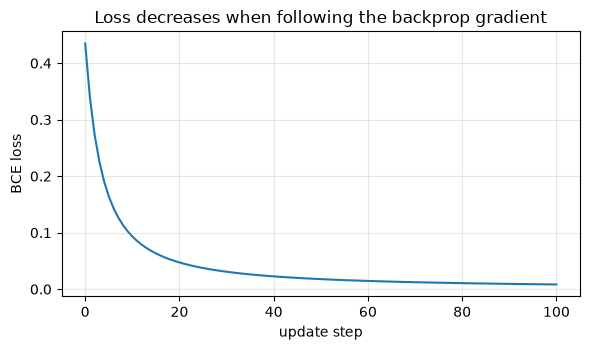

In [6]:
lr = 0.5
W1_t, b1_t, W2_t, b2_t = W1.copy(), b1.copy(), W2.copy(), b2
history = []
for step in range(101):
    c = forward(x, W1_t, b1_t, W2_t, b2_t)
    history.append(bce(c["y_pred"], y_true))
    g = backward(c, W2_t, y_true)
    W1_t, b1_t, W2_t, b2_t = (
        W1_t - lr * g["dW1"],
        b1_t - lr * g["db1"],
        W2_t - lr * g["dW2"],
        b2_t - lr * g["db2"],
    )

history = np.array(history)
print(f"1번 갱신 후 손실: {history[0]:.4f} → {history[1]:.4f}")
print(f"100번 갱신 후 손실: {history[100]:.4f}, ŷ = {c['y_pred']:.4f}")
assert history[1] < history[0] and np.all(np.diff(history) < 0)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(history)
ax.set_xlabel("update step")
ax.set_ylabel("BCE loss")
ax.set_title("Loss decreases when following the backprop gradient")
ax.grid(alpha=0.3)
fig.tight_layout()
OUTPUT_DIR.mkdir(exist_ok=True)
fig.savefig(OUTPUT_DIR / "backprop_training.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. 정리

- 역전파는 $L \to \hat y \to z_2 \to (W_2, a_1) \to z_1 \to W_1$ 순서로 **윗단 기울기 × 국소 도함수** 를 곱한다.
- Sigmoid + BCE에서는 $\partial L/\partial z_2 = \hat y - y$ 로 약분되어, 출력층 오차가 그대로 아래로 전파된다.
- $\partial L/\partial W$ 는 항상 (이 층의 $\partial L/\partial z$) × (이 층으로 들어온 입력)의 외적이고, $\partial L/\partial a$ 는 가중치를 곱해 한 층 아래로 보낸 값이다.
- 손계산 11개 항목이 NumPy와 소수점 넷째 자리까지 일치했고, 9개 파라미터 전부 중심차분과 $10^{-8}$ 이내로 일치했다.
- 이 규칙을 일반 계산 그래프로 확장해 자동화한 것이 이후 미션의 AutoGrad 엔진이다.